# Assignment 13
# Planning a Fast Rescue Boat Mission with an Extended Kalman Filter

In [25]:
import numpy as np
from matplotlib import pyplot as plt

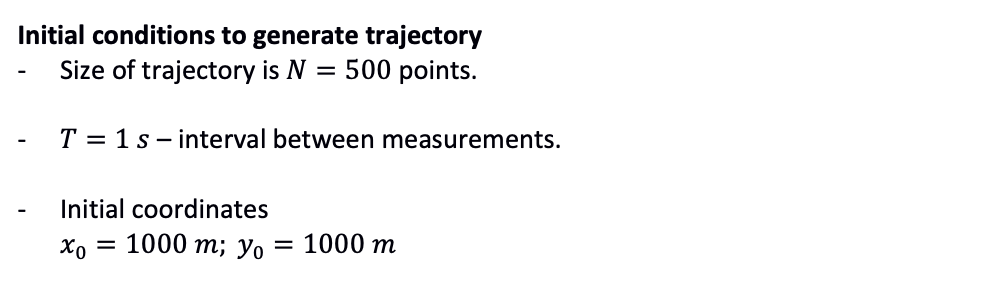

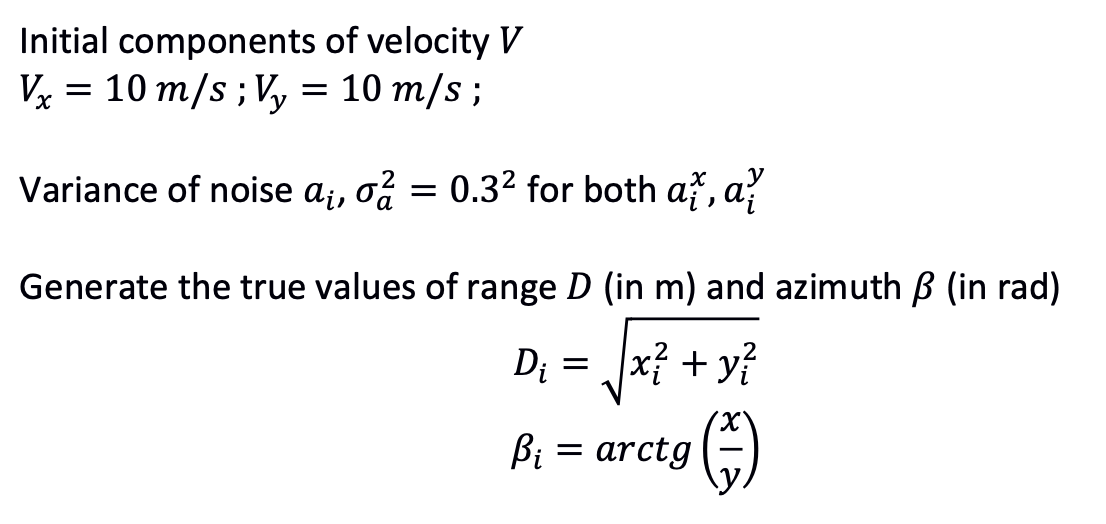

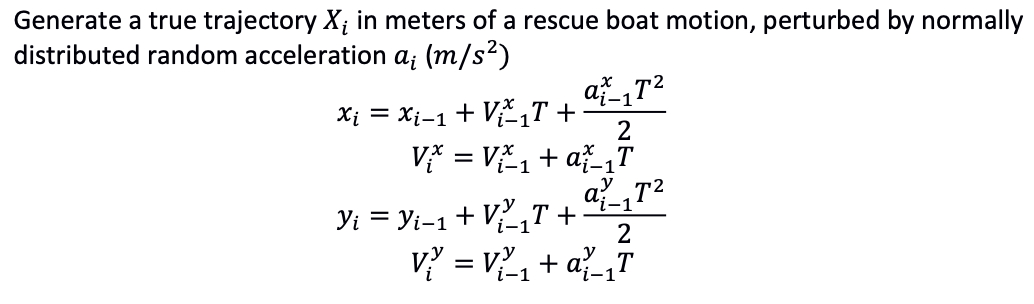

In [26]:
# make a folder to store generated trajectories
from pathlib import Path

output_dir = Path("common_files")
output_dir.mkdir(parents=True, exist_ok=True)

# define the constants
SIZE = 500
X_INIT = 1000   # m
Y_INIT = 1000   # m
T = 1           # s
Vx_INIT = 10    # m/s
Vy_INIT = 10    # m/s
VARIANCE_A = 0.3**2
SIGMA_A = np.sqrt(VARIANCE_A)

# generate a true trajectory
def generate_true_trajectory(size=SIZE, dt=T, sigma_a=SIGMA_A, seed=None):
    states = np.empty((size, 4))
    states[0] = X_INIT, Vx_INIT, Y_INIT, Vy_INIT
    x, vx, y, vy = states.T

    rng = np.random.default_rng(seed)
    accelerations = rng.normal(0.0, sigma_a, size=(size - 1, 2))
    for i, (ax, ay) in enumerate(accelerations, start=1):
        x[i] = x[i - 1] + vx[i - 1] * dt + 0.5 * ax * dt**2
        vx[i] = vx[i - 1] + ax * dt
        y[i] = y[i - 1] + vy[i - 1] * dt + 0.5 * ay * dt**2
        vy[i] = vy[i - 1] + ay * dt

    true_range = np.sqrt(x**2 + y**2)
    true_azimuth = np.arctan2(x, y)
    return true_range, true_azimuth

D_true, beta_true = generate_true_trajectory()

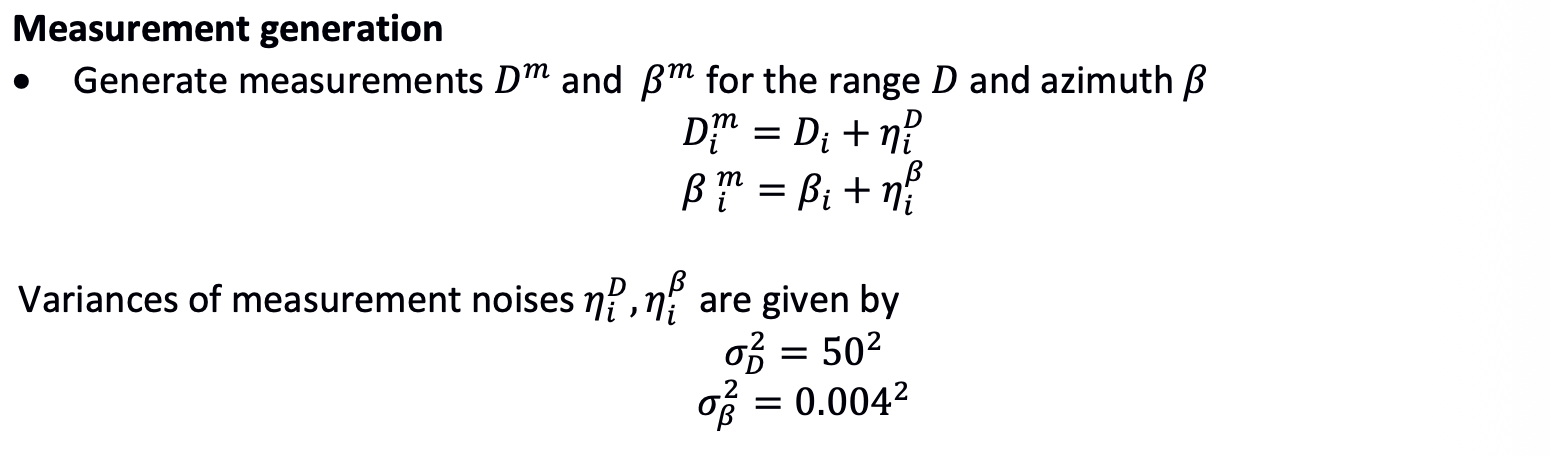

In [27]:
# define the constants
VARIANCE_D = 50**2
SIGMA_D = np.sqrt(VARIANCE_D)
VARIANCE_BETA = 0.004**2
SIGMA_BETA = np.sqrt(VARIANCE_BETA)

# generate measurements
def generate_measurements(true_range, true_azimuth, seed=None):
    rng = np.random.default_rng(seed)
    range_noise = rng.normal(0.0, SIGMA_D, size=true_range.shape)
    azimuth_noise = rng.normal(0.0, SIGMA_BETA, size=true_azimuth.shape)
    return true_range + range_noise, true_azimuth + azimuth_noise

D_measured, beta_measured = generate_measurements(D_true, beta_true)

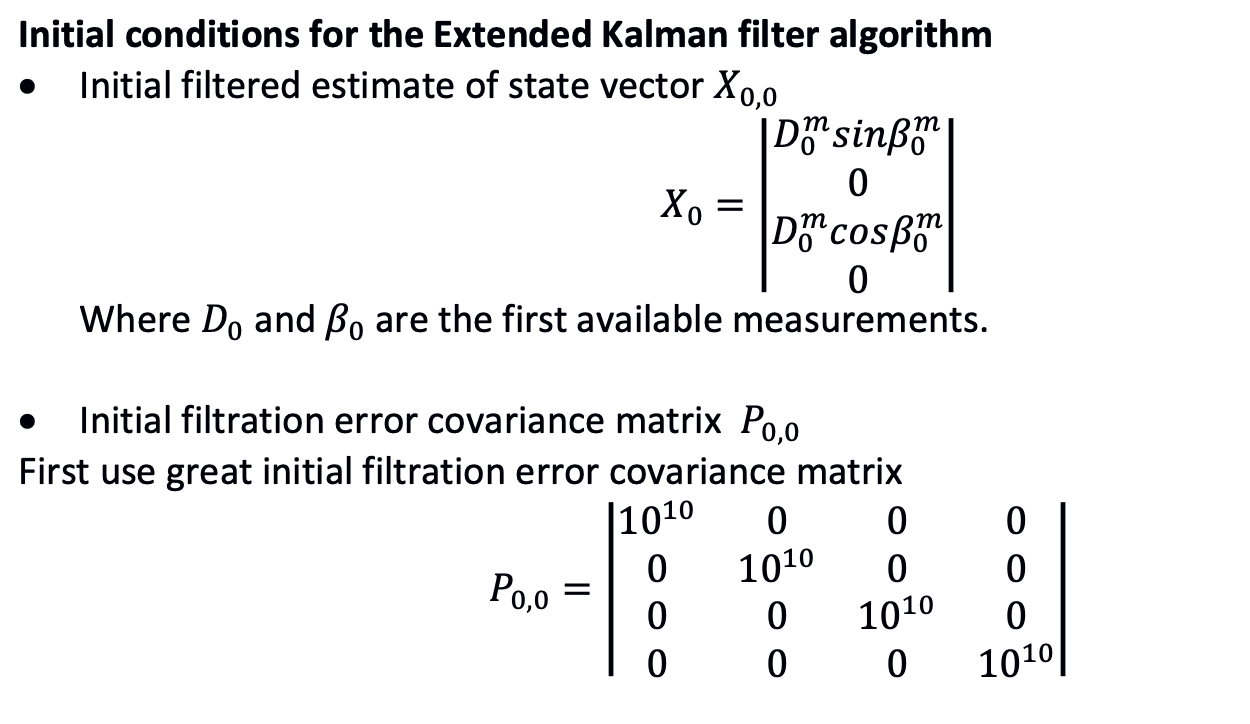

In [28]:
# initial conditions for the Extended Kalman filter (EKF) algorithm

D0_m = D_measured[0]
beta0_m = beta_measured[0]

# initial filtered estimate of state vector 
X_0_0 = np.array([[D0_m * np.sin(beta0_m)],
               [0],
               [D0_m * np.cos(beta0_m)],
               [0]])

# initial filtration error covariance matrix
P_0_0 = np.eye(4) * 10**10

In [29]:
# EKF settings

# transition matrix
PHI = np.eye(4)
PHI[0, 1] = T
PHI[2, 3] = T

# input matrix
G = np.zeros((4, 2))
G[0, 0] = G[2, 1] = 0.5 * T**2
G[1, 0] = G[3, 1] = T

# state noise covariance matrix
Q = G @ G.T * VARIANCE_A

# measurement noise covariance matrix
R = np.array([[VARIANCE_D, 0],
              [0, VARIANCE_BETA]])

In [30]:
# find a measurement function derivative (Jacobian) with respect to X_{i+1} at point X_hat_{i+1},i for the EKF algorithm
def _measurement_jacobian(X_pred):
    x_pred, _, y_pred, _ = np.asarray(X_pred, dtype=float).reshape(4)
    range = np.sqrt(x_pred**2 + y_pred**2)
    if range == 0:
        raise ValueError("The measurement Jacobian is undefined!")

    return np.array([
        [x_pred / range, 0.0, y_pred / range, 0.0],
        [y_pred / (x_pred**2 + y_pred**2), 0.0, -x_pred / (x_pred**2 + y_pred**2), 0.0]
    ])

In [ ]:
# EKF algorithm
def EKF(measured_ranges, measured_azimuths, PHI=PHI, Q=Q, R=R, X_0_0=X_0_0, P_0_0=P_0_0):
    measurements = np.column_stack((measured_ranges, measured_azimuths))  # measurements has shape (500, 2)
    size = len(measurements) 

    # arrays to store the results of the filter at every step i
    X_pred = np.zeros((size, 4, 1))   # predicted state X_{i+1,i}
    P_pred = np.zeros((size, 4, 4))   # prediction error covariance P_{i+1,i}
    X_filt = np.zeros((size, 4, 1))   # filtered state X_{i,i}
    P_filt = np.zeros((size, 4, 4))   # filtration error covariance P_{i,i}
    K = np.zeros((size, 4, 2))        # filter gain K_i

    X_filt[0], P_filt[0] = X_0_0, P_0_0
    for i in range(1, size):
        # prediction
        X_pred[i] = PHI @ X_filt[i - 1]
        P_pred[i] = PHI @ P_filt[i - 1] @ PHI.T + Q

        # find a measurement residual
        x_pred, _, y_pred, _ = X_pred[i, :, 0]
        h_X_pred = np.array([[np.sqrt(x_pred**2 + y_pred**2)], 
                           [np.arctan2(x_pred, y_pred)]])
        residual = measurements[i].reshape(2, 1) - h_X_pred
        residual[1, 0] = (residual[1, 0] + np.pi) % (2 * np.pi) - np.pi  # wrap the azimuth

        # filtration
        K[i] = (P_pred[i] @ _measurement_jacobian(X_pred[i]).T 
                @ np.linalg.inv(_measurement_jacobian(X_pred[i]) 
                @ P_pred[i] @ _measurement_jacobian(X_pred[i]).T + R))
        X_filt[i] = X_pred[i] + K[i] @ residual
        P_filt[i] = (np.eye(4) - K[i] @ _measurement_jacobian(X_pred[i])) @ P_pred[i]

    ranges_pred = np.sqrt(X_pred[:, 0, 0]**2 + X_pred[:, 2, 0]**2)
    azimuths_pred = np.arctan2(X_pred[:, 0, 0], X_pred[:, 2, 0])
    ranges_pred[0] = np.nan  
    azimuths_pred[0] = np.nan

    ranges_filt = np.sqrt(X_filt[:, 0, 0]**2 + X_filt[:, 2, 0]**2)
    azimuths_filt = np.arctan2(X_filt[:, 0, 0], X_filt[:, 2, 0])

    return ranges_pred, azimuths_pred, ranges_filt, azimuths_filt

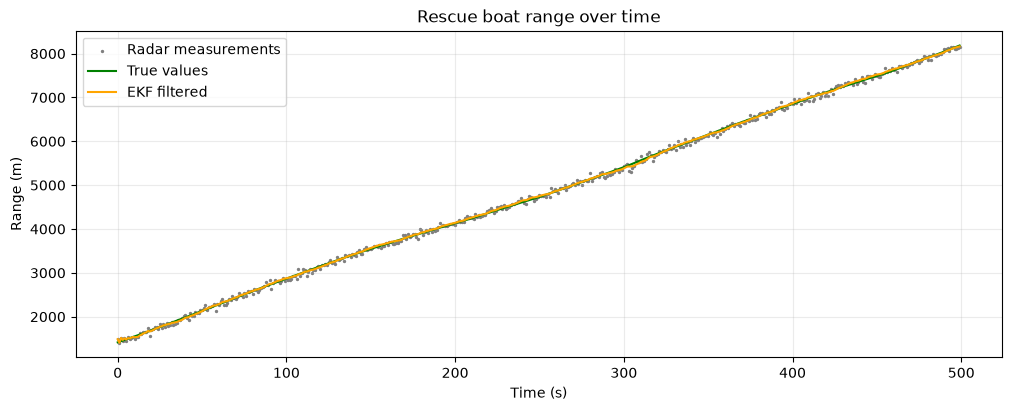

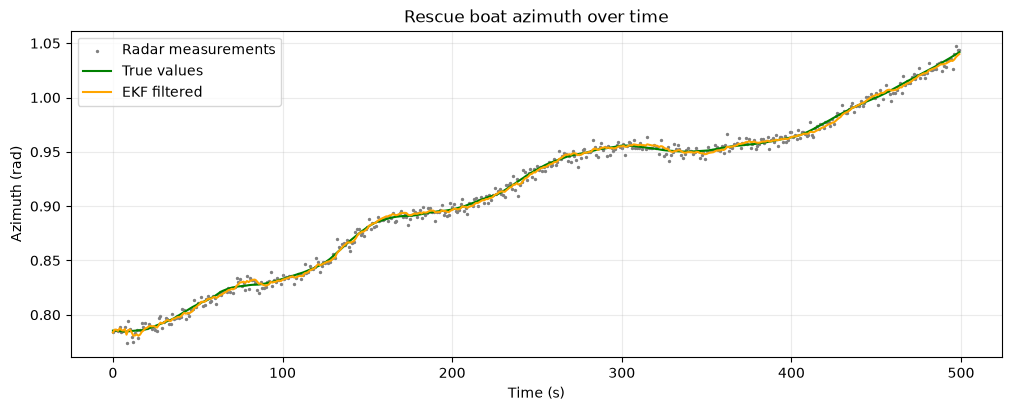

In [49]:
# plot the true values, measurements, and EKF estimates of azimuth and range for one trajectory
_, _, range_filt, azimuth_filt = EKF(
    D_measured, beta_measured
)
time = np.arange(D_true.size) * T

for title, ylabel, truth, measured, filtered in [
    ("Rescue boat range over time", "Range (m)", D_true, D_measured, range_filt),
    ("Rescue boat azimuth over time", "Azimuth (rad)", beta_true, beta_measured, azimuth_filt),
]:
    fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
    ax.scatter(time, measured, label="Radar measurements", s=2, color="grey")
    ax.plot(time, truth, label="True values", color="green")
    ax.plot(time, filtered, label="EKF filtered", color="orange")
    ax.set(title=title, xlabel="Time (s)", ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

plt.show()

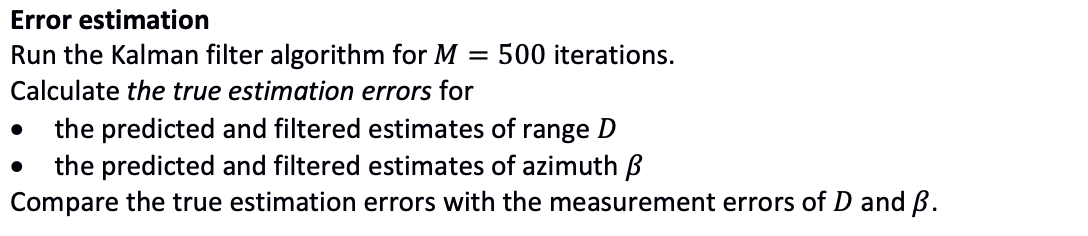

In [42]:
# account for angle wrapping in error estimation
def azimuth_error(estimate, truth):
    return (estimate - truth + np.pi) % (2 * np.pi) - np.pi

M = 500

pred_range_true_errors = np.zeros((M, SIZE))
filt_range_true_errors = np.zeros((M, SIZE))
pred_azimuth_true_errors = np.zeros((M, SIZE))
filt_azimuth_true_errors = np.zeros((M, SIZE))
meas_azimuth_true_errors = np.zeros((M, SIZE))
meas_range_true_errors = np.zeros((M, SIZE))

for m in range(M):
    true_ranges, true_azimuths = generate_true_trajectory()
    measured_ranges, measured_azimuths = generate_measurements(true_ranges, true_azimuths)
    ranges_pred, azimuths_pred, ranges_filt, azimuths_filt = EKF(measured_ranges, measured_azimuths)

    pred_range_true_errors[m] = (
            ranges_pred - true_ranges
        )   
    filt_range_true_errors[m] = (
            ranges_filt - true_ranges
        )
    meas_range_true_errors[m] = (
            measured_ranges - true_ranges
        )

    pred_azimuth_true_errors[m] = (
            azimuth_error(azimuths_pred, true_azimuths)
        )
    filt_azimuth_true_errors[m] = (
            azimuth_error(azimuths_filt, true_azimuths)
        )
    meas_azimuth_true_errors[m] = (
            azimuth_error(measured_azimuths, true_azimuths)
        )
    

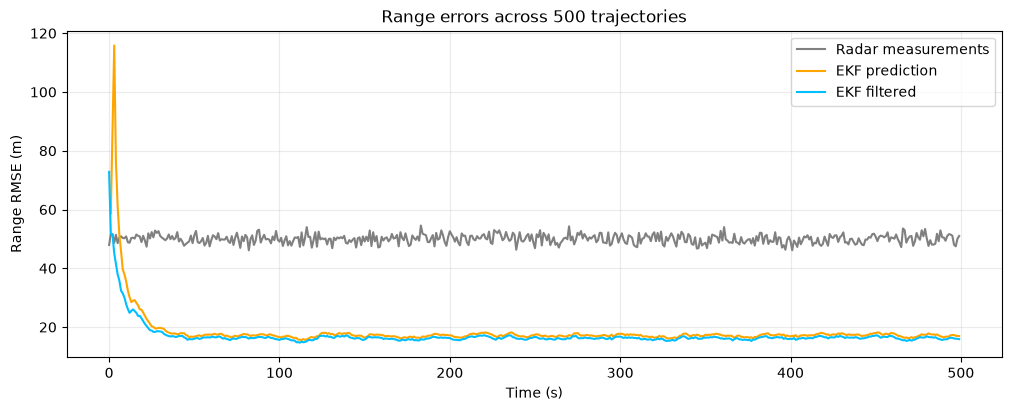

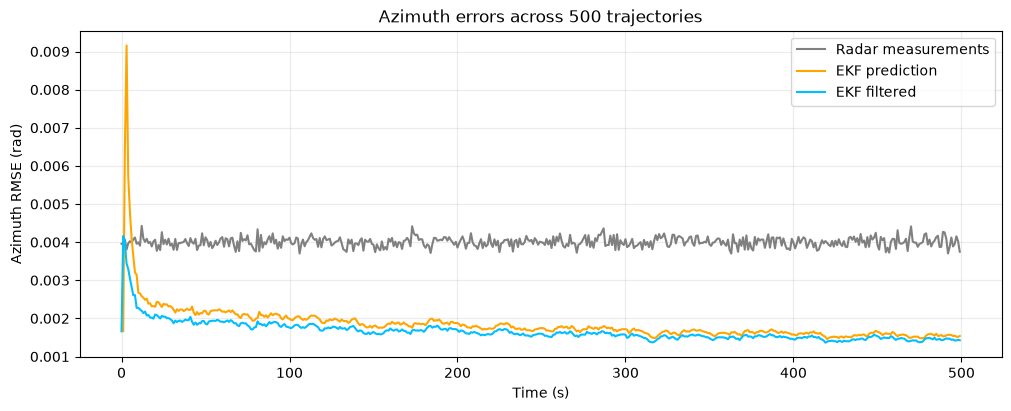

In [43]:
def plot_rmse(ax, measured, predicted, filtered, ylabel, dt=T):
    time = np.arange(measured.shape[1]) * dt

    for errors, label, color in [
        (measured,  "Radar measurements", "grey"),
        (predicted, "EKF prediction", "orange"),
        (filtered,  "EKF filtered", "deepskyblue")
    ]:
        rmse = np.sqrt(np.mean(errors**2, axis=0))
        ax.plot(time, rmse, label=label, color=color)

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)


fig_range, ax_range = plt.subplots(figsize=(10, 4), layout="constrained")
plot_rmse(ax_range, meas_range_true_errors, pred_range_true_errors,
          filt_range_true_errors, "Range RMSE (m)")
ax_range.set_title(f"Range errors across {M} trajectories")
ax_range.set_xlabel("Time (s)")
ax_range.legend()

fig_azimuth, ax_azimuth = plt.subplots(figsize=(10, 4), layout="constrained")
plot_rmse(ax_azimuth, meas_azimuth_true_errors, pred_azimuth_true_errors,
          filt_azimuth_true_errors, "Azimuth RMSE (rad)")
ax_azimuth.set_title(f"Azimuth errors across {M} trajectories")
ax_azimuth.set_xlabel("Time (s)")
ax_azimuth.legend()

plt.show()